# Baseline Models v2 — Fair Comparison on RIRD
**Group:** Flower | **Authors:** Ton (st127004) · Sam (st127012)

This notebook replaces `baseline_models.ipynb`. It fixes three weaknesses of the first run:

| # | Weakness in v1 | Fix in this notebook |
|---|---|---|
| 1 | BM25 scored one concatenated document per restaurant, dense scored per review then mean-pooled — different units, different aggregation | Both models score the **same unit** (review or sentence) and use the **same aggregation** (max, mean, top-k mean) |
| 2 | Only mean scores were reported | **Bootstrap 95% confidence intervals** and a **paired randomization test** over queries, with Holm correction |
| 3 | No reference floors | **Random**, **review-count** and **popularity (leave-one-query-out)** rows in the comparison table |

The two v1 models are kept as reference rows so the old and new numbers can be compared.

### Before running in Colab
1. `Runtime → Change runtime type → GPU` (encoding is slow on CPU).
2. Upload these three files to `/content/`: `PMD.csv`, `50_restaurants_all_rates.csv`, `eval_utils.py`.
3. `Runtime → Run all`.

**Metrics:** MAP · MRR · nDCG@5 · nDCG@10 · Recall@5 · Recall@10 · P@5 · P@10
**Labels:** binary (`If only Low or High`) + graded (annotator vote sum 0–5) for nDCG

## 0. Setup & Configuration

In [9]:
#!pip install -q rank-bm25

In [10]:
import re, sys
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# ── Experiment configuration ────────────────────────────────────────────────
UNIT        = 'sentence'    # 'review' or 'sentence' — the unit BOTH models score
TOP_KS      = (3, 5, 10)  # k values for top-k mean aggregation
MODEL_NAME  = 'sentence-transformers/paraphrase-multilingual-mpnet-base-v2'
MAX_SEQ_LEN = 256         # v1 used the model default (128), which cut off long reviews
BATCH_SIZE  = 32
SEED        = 42
N_SHUFFLES  = 200         # random-ranking repetitions
N_RESAMPLES = 10_000      # bootstrap / randomization resamples
PRIMARY     = 'nDCG@10'   # metric used for the significance tests and the plot

# ── Locate files (Colab: /content, local: repo layout) ──────────────────────
HERE = Path.cwd()
SEARCH_DIRS = [
    Path('/content'), HERE, HERE / 'baselines',
    HERE / 'datasets' / 'rir_data-main', HERE / 'datasets' / 'rir_data-main' / 'reviews',
    HERE.parent / 'datasets' / 'rir_data-main', HERE.parent / 'datasets' / 'rir_data-main' / 'reviews',
]

def find_file(name: str) -> Path:
    for d in SEARCH_DIRS:
        if (d / name).is_file():
            return d / name
    raise FileNotFoundError(f'{name} not found — upload it to /content/ (looked in {[str(d) for d in SEARCH_DIRS]})')

sys.path.insert(0, str(find_file('eval_utils.py').parent))
from eval_utils import average_precision, mrr, ndcg_at_k, recall_at_k, precision_at_k

CACHE_DIR = HERE / 'cache'
CACHE_DIR.mkdir(exist_ok=True)

print('UNIT      :', UNIT)
print('CACHE_DIR :', CACHE_DIR)

UNIT      : sentence
CACHE_DIR : /content/cache


## 1. Data Loading

Two RIRD files:
- `50_restaurants_all_rates.csv` — 29 k reviews across 50 restaurants
- `PMD.csv` — 100 queries × 50 restaurants, 5 annotators each

In [11]:
# ── Reviews ─────────────────────────────────────────────────────────────────
rev = pd.read_csv(find_file('50_restaurants_all_rates.csv'))
rev['review_text'] = rev['review_text'].fillna('').astype(str)
print(f"Reviews: {rev.shape}  |  unique restaurants: {rev['business_id'].nunique()}")

# ── PMD ─────────────────────────────────────────────────────────────────────
pmd_raw = pd.read_csv(find_file('PMD.csv'))
pmd = pmd_raw.drop_duplicates().copy()
print(f'PMD rows after dedup: {len(pmd)}  (was {len(pmd_raw)})')

ANNOTATORS = ['Annotator1','Annotator2','Annotator3','Annotator4','Annotator5']
AGG_COL    = 'If only Low or  High'   # note: double space — actual column name in PMD.csv

# Fail loudly instead of silently filling missing labels with 0
assert pmd[ANNOTATORS + [AGG_COL]].notna().all().all(), 'PMD has missing labels'
pmd[ANNOTATORS + [AGG_COL]] = pmd[ANNOTATORS + [AGG_COL]].astype(int)

Reviews: (29168, 9)  |  unique restaurants: 50
PMD rows after dedup: 5000  (was 5001)


## 2. Build Ground Truth (qrels)

| Name | Type | Used for |
|---|---|---|
| `binary_qrels` | `{query -> set of relevant business_ids}` | MAP, MRR, Recall, P |
| `graded_qrels` | `{query -> {business_id -> annotator_vote_sum (0–5)}}` | graded nDCG |

In [12]:
name_to_bid = (
    rev.drop_duplicates('business_id')
       .set_index('name')['business_id']
       .to_dict()
)
missing = set(pmd['Restaurant name']) - set(name_to_bid)
assert not missing, f'PMD restaurants with no reviews: {missing}'

pmd['business_id'] = pmd['Restaurant name'].map(name_to_bid)
pmd['grade']       = pmd[ANNOTATORS].sum(axis=1)

binary_qrels: dict = {}
graded_qrels: dict = {}
for query, grp in pmd.groupby('query'):
    binary_qrels[query] = set(grp.loc[grp[AGG_COL] == 1, 'business_id'])
    graded_qrels[query] = dict(zip(grp['business_id'], grp['grade']))

queries    = sorted(binary_qrels)
corpus_ids = sorted(rev['business_id'].unique())

n_rel = pd.Series({q: len(binary_qrels[q]) for q in queries})
print(f'Queries: {len(queries)}  |  restaurants: {len(corpus_ids)}')
print(f'Relevant restaurants per query: mean {n_rel.mean():.1f}, median {n_rel.median():.1f}, '
      f'min {n_rel.min()}, max {n_rel.max()}')

Queries: 100  |  restaurants: 50
Relevant restaurants per query: mean 13.5, median 8.5, min 1, max 46


## 3. Shared Retrieval Units

Both models score the same list of text units. `UNIT = 'review'` uses each review as one unit;
`UNIT = 'sentence'` splits reviews into sentences first.

In [13]:
def split_sentences(text: str):
    return [s.strip() for s in re.split(r'(?<=[.!?])\s+|\n+', text) if s.strip()]

if UNIT == 'review':
    units = (
        rev.reset_index(names='review_row_id')
           [['review_row_id', 'business_id', 'review_text']]
           .rename(columns={'review_text': 'text'})
    )
elif UNIT == 'sentence':
    units = (
        rev.reset_index(names='review_row_id')
           .assign(text=lambda frame: frame['review_text'].map(split_sentences))
           .explode('text')[['review_row_id', 'business_id', 'text']]
    )
else:
    raise ValueError(f'Unknown UNIT: {UNIT!r}')

units = units.dropna(subset=['text'])
units = units[units['text'].str.strip().ne('')].reset_index(drop=True)

unit_bids = units['business_id'].to_numpy()
unit_idx  = {bid: np.flatnonzero(unit_bids == bid) for bid in corpus_ids}   # restaurant -> unit positions

per_rest = pd.Series({bid: len(ix) for bid, ix in unit_idx.items()})
print(f'{len(units):,} {UNIT}s  |  per restaurant: min {per_rest.min()}, median {per_rest.median():.0f}, max {per_rest.max()}')

240,660 sentences  |  per restaurant: min 2707, median 4014, max 16015


## 4. Shared Aggregation and Evaluation

Every model produces a score matrix `S` of shape `(n_queries, n_units)`.
The **same** `aggregate()` turns it into restaurant scores for BM25 and for dense:

| Aggregation | Restaurant score |
|---|---|
| `max` | best single unit |
| `mean` | average over all units |
| `top-k mean` | average of the k best units |

`per_query_metrics()` keeps one value per query, which the significance tests in Section 8 need.

In [14]:
AGGS = [('max', 'max', None), ('mean', 'mean', None)] + [(f'top-{k} mean', 'topk', k) for k in TOP_KS]

def aggregate(S: np.ndarray, how: str, k: int = None) -> np.ndarray:
    """(n_queries, n_units) unit scores -> (n_queries, n_restaurants) restaurant scores."""
    out = np.empty((S.shape[0], len(corpus_ids)), dtype=np.float64)
    for j, bid in enumerate(corpus_ids):
        sub = S[:, unit_idx[bid]]
        if how == 'max':
            out[:, j] = sub.max(axis=1)
        elif how == 'mean':
            out[:, j] = sub.mean(axis=1)
        elif how == 'topk':
            kk = min(k, sub.shape[1])
            out[:, j] = np.partition(sub, -kk, axis=1)[:, -kk:].mean(axis=1)
        else:
            raise ValueError(how)
    return out

def to_rankings(R: np.ndarray) -> dict:
    """Restaurant score matrix -> {query: [business_id best-first]}. Ties broken by business_id."""
    return {q: [corpus_ids[i] for i in np.argsort(-R[qi], kind='stable')] for qi, q in enumerate(queries)}

KS      = (5, 10)
METRICS = ['MAP', 'MRR', 'nDCG@5', 'nDCG@10', 'Recall@5', 'Recall@10', 'P@5', 'P@10']

def per_query_metrics(rankings: dict) -> pd.DataFrame:
    """One row per query, one column per metric."""
    rows = {}
    for q in queries:
        ranked, rel, graded = rankings[q], binary_qrels[q], graded_qrels[q]
        row = {'MAP': average_precision(ranked, rel), 'MRR': mrr(ranked, rel)}
        for k in KS:
            row[f'nDCG@{k}']   = ndcg_at_k(ranked, graded, k)
            row[f'Recall@{k}'] = recall_at_k(ranked, rel, k)
            row[f'P@{k}']      = precision_at_k(ranked, rel, k)
        rows[q] = row
    return pd.DataFrame.from_dict(rows, orient='index').loc[queries, METRICS]

per_query: dict = {}   # model name -> per-query metric DataFrame
retrieval_runs: dict = {}   # model -> unit scores, restaurant scores, and rankings for A4/B1/B2

def add_model(name: str, rankings: dict):
    per_query[name] = per_query_metrics(rankings)
    print(f'{name:<34} {PRIMARY} {per_query[name][PRIMARY].mean():.4f}   MAP {per_query[name]["MAP"].mean():.4f}')

def add_retrieval_model(name: str, unit_scores: np.ndarray, how: str, k: int = None):
    """Register a shared-unit retrieval run and retain data needed for A4/B1/B2."""
    restaurant_scores = aggregate(unit_scores, how, k)
    rankings = to_rankings(restaurant_scores)
    add_model(name, rankings)
    retrieval_runs[name] = {
        'unit_scores': unit_scores,
        'restaurant_scores': restaurant_scores,
        'how': how,
        'k': k,
        'rankings': rankings,
    }


## 5. BM25 on Shared Units

One BM25 index over all units (not one giant document per restaurant), so IDF can
tell common words from rare ones. The v1 concatenated-document BM25 is kept as a reference row.

In [15]:
from rank_bm25 import BM25Okapi

def simple_tokenise(text: str):
    return re.sub(r'[^a-z0-9\s]', ' ', text.lower()).split()

unit_tokens = [simple_tokenise(t) for t in tqdm(units['text'], desc='Tokenising units')]
bm25_units  = BM25Okapi(unit_tokens)

S_bm25 = np.vstack([
    bm25_units.get_scores(simple_tokenise(q)) for q in tqdm(queries, desc='BM25 queries')
]).astype(np.float32)
print('BM25 unit score matrix:', S_bm25.shape)

for label, how, k in AGGS:
    add_retrieval_model(f'BM25 | {label}', S_bm25, how, k)

Tokenising units:   0%|          | 0/240660 [00:00<?, ?it/s]

BM25 queries:   0%|          | 0/100 [00:00<?, ?it/s]

BM25 unit score matrix: (100, 240660)
BM25 | max                         nDCG@10 0.5459   MAP 0.4719
BM25 | mean                        nDCG@10 0.5479   MAP 0.5037
BM25 | top-3 mean                  nDCG@10 0.5871   MAP 0.5147
BM25 | top-5 mean                  nDCG@10 0.5975   MAP 0.5248
BM25 | top-10 mean                 nDCG@10 0.6093   MAP 0.5359


In [16]:
# v1 reference: one concatenated document per restaurant
concat_tokens = [[tok for i in unit_idx[bid] for tok in unit_tokens[i]] for bid in corpus_ids]
bm25_concat   = BM25Okapi(concat_tokens)
R_concat      = np.vstack([bm25_concat.get_scores(simple_tokenise(q)) for q in queries])
add_model('BM25 | concat doc (v1)', to_rankings(R_concat))

BM25 | concat doc (v1)             nDCG@10 0.6211   MAP 0.5612


## 6. Dense on Shared Units

Each unit is encoded once and cached to disk. Unit scores are cosine similarities to the query,
then aggregated with the same `aggregate()` used for BM25.
The v1 mean-pooled restaurant vector is kept as a reference row.

In [17]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer(MODEL_NAME)
embedder.max_seq_length = MAX_SEQ_LEN
print(f'Loaded: {MODEL_NAME}  |  device: {embedder.device}  |  max_seq_length: {embedder.max_seq_length}')

# How many units are still cut off at MAX_SEQ_LEN? (estimated on a sample)
sample = units['text'].sample(min(2000, len(units)), random_state=SEED).tolist()
tok_lens = np.array([len(ids) for ids in embedder.tokenizer(sample, truncation=False)['input_ids']])
print(f'Units longer than {MAX_SEQ_LEN} tokens: {(tok_lens > MAX_SEQ_LEN).mean():.1%}  '
      f'(longer than 128, the v1 limit: {(tok_lens > 128).mean():.1%})')

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.12k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/723 [00:00<?, ?B/s]

...

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loaded: sentence-transformers/paraphrase-multilingual-mpnet-base-v2  |  device: cuda:0  |  max_seq_length: 256
Units longer than 256 tokens: 0.0%  (longer than 128, the v1 limit: 0.1%)


In [18]:
cache_file = CACHE_DIR / f"emb_{MODEL_NAME.split('/')[-1]}_{UNIT}_len{MAX_SEQ_LEN}.npy"

E_raw = np.load(cache_file) if cache_file.is_file() else None
if E_raw is None or E_raw.shape[0] != len(units):
    print(f'Encoding {len(units):,} {UNIT}s...')
    E_raw = embedder.encode(
        units['text'].tolist(),
        batch_size=BATCH_SIZE,
        show_progress_bar=True,
        convert_to_numpy=True,
    )
    np.save(cache_file, E_raw)
else:
    print(f'Loaded cached embeddings: {cache_file.name}')
print(f'Embeddings shape: {E_raw.shape}')

def l2_normalise(X: np.ndarray) -> np.ndarray:
    return X / np.clip(np.linalg.norm(X, axis=1, keepdims=True), 1e-12, None)

E = l2_normalise(E_raw)
Q = l2_normalise(embedder.encode(queries, show_progress_bar=False, convert_to_numpy=True))

S_dense = (Q @ E.T).astype(np.float32)   # cosine similarity, (n_queries, n_units)
print('Dense unit score matrix:', S_dense.shape)

for label, how, k in AGGS:
    add_retrieval_model(f'Dense | {label}', S_dense, how, k)

Encoding 240,660 sentences...


Batches:   0%|          | 0/7521 [00:00<?, ?it/s]

Embeddings shape: (240660, 768)
Dense unit score matrix: (100, 240660)
Dense | max                        nDCG@10 0.6107   MAP 0.5460
Dense | mean                       nDCG@10 0.5869   MAP 0.5331
Dense | top-3 mean                 nDCG@10 0.6639   MAP 0.5933
Dense | top-5 mean                 nDCG@10 0.6733   MAP 0.6070
Dense | top-10 mean                nDCG@10 0.6815   MAP 0.6177


## 6a. A3 — Review-volume control

This diagnostic addresses the unresolved volume component of feedback F2. It is only run on the review-level experiment: every restaurant is sampled to the same number of source reviews, while the already-computed BM25 and dense unit scores are reused. The sampling is deterministic and preserves the row alignment needed for cached embeddings.

The uncontrolled run reports score-versus-review-count correlations. In the controlled run, the effective review count is constant by design, so its correlation is correctly reported as undefined; we also report correlation with the original uncapped counts as a residual diagnostic. A3 does not establish explanation faithfulness (B1/B2), Thai taste validity (C3-C7), or literature coverage (D1).

In [20]:
if UNIT != 'review':
    print("Skipping A3 volume control: it is defined only for UNIT = 'review'.")
else:

    A3_REVIEWS_PER_RESTAURANT = 400
    a3_rng = np.random.default_rng(SEED)

    review_counts = rev.groupby('business_id').size().reindex(corpus_ids)
    if review_counts.isna().any() or (review_counts < A3_REVIEWS_PER_RESTAURANT).any():
        too_small = review_counts[review_counts < A3_REVIEWS_PER_RESTAURANT]
        raise ValueError(
            f'Cannot sample {A3_REVIEWS_PER_RESTAURANT} reviews for every restaurant: {too_small.to_dict()}'
        )

    sampled_review_ids = {
        bid: a3_rng.choice(
            rev.index[rev['business_id'].eq(bid)].to_numpy(),
            size=A3_REVIEWS_PER_RESTAURANT,
            replace=False,
        )
        for bid in corpus_ids
    }
    sampled_review_rows = set(np.concatenate(list(sampled_review_ids.values())))
    sampled_positions = np.flatnonzero(units['review_row_id'].isin(sampled_review_rows).to_numpy())
    if len(sampled_positions) != A3_REVIEWS_PER_RESTAURANT * len(corpus_ids):
        raise AssertionError('The sampled source reviews and active review units are misaligned.')

    sampled_unit_idx = {
        bid: np.array([pos for pos in sampled_positions if unit_bids[pos] == bid], dtype=int)
        for bid in corpus_ids
    }
    assert all(len(ix) == A3_REVIEWS_PER_RESTAURANT for ix in sampled_unit_idx.values())

    def aggregate_with_unit_idx(S: np.ndarray, how: str, k: int, active_unit_idx: dict) -> np.ndarray:
        out = np.empty((S.shape[0], len(corpus_ids)), dtype=np.float64)
        for j, bid in enumerate(corpus_ids):
            sub = S[:, active_unit_idx[bid]]
            if how == 'max':
                out[:, j] = sub.max(axis=1)
            elif how == 'mean':
                out[:, j] = sub.mean(axis=1)
            elif how == 'topk':
                kk = min(k, sub.shape[1])
                out[:, j] = np.partition(sub, -kk, axis=1)[:, -kk:].mean(axis=1)
            else:
                raise ValueError(how)
        return out

    def score_count_correlations(scores: np.ndarray, counts: pd.Series, label: str) -> pd.DataFrame:
        rows = []
        count_values = counts.to_numpy(dtype=float)
        for query_i, query in enumerate(queries):
            row_scores = scores[query_i]
            rows.append({
                'run': label,
                'query': query,
                'pearson_score_vs_count': pd.Series(row_scores).corr(pd.Series(count_values), method='pearson'),
                'spearman_score_vs_count': pd.Series(row_scores).corr(pd.Series(count_values), method='spearman'),
            })
        pooled = pd.DataFrame({'score': scores.ravel(), 'count': np.tile(count_values, scores.shape[0])})
        rows.append({
            'run': label,
            'query': '__pooled__',
            'pearson_score_vs_count': pooled['score'].corr(pooled['count'], method='pearson'),
            'spearman_score_vs_count': pooled['score'].corr(pooled['count'], method='spearman'),
        })
        return pd.DataFrame(rows)

    a3_metrics = []
    a3_correlations = []
    original_count = review_counts.astype(float)
    controlled_count = pd.Series(A3_REVIEWS_PER_RESTAURANT, index=corpus_ids, dtype=float)

    for model_name, scores in [('BM25', S_bm25), ('Dense', S_dense)]:
        for label, how, k in AGGS:
            full_scores = aggregate(scores, how, k)
            controlled_scores = aggregate_with_unit_idx(scores, how, k, sampled_unit_idx)
            for run, restaurant_scores, effective_count in [
                ('uncontrolled', full_scores, original_count),
                ('controlled_400', controlled_scores, controlled_count),
            ]:
                rankings = to_rankings(restaurant_scores)
                metrics = per_query_metrics(rankings).mean()
                a3_metrics.append({'model': model_name, 'aggregation': label, 'run': run, **metrics.to_dict()})
                corr = score_count_correlations(restaurant_scores, effective_count, f'{model_name} | {label} | {run}')
                corr['model'] = model_name
                corr['aggregation'] = label
                corr['count_definition'] = 'effective_reviews_used'
                a3_correlations.append(corr)
                if run == 'controlled_400':
                    residual = score_count_correlations(restaurant_scores, original_count, f'{model_name} | {label} | {run} | original_count')
                    residual['model'] = model_name
                    residual['aggregation'] = label
                    residual['count_definition'] = 'original_uncapped_reviews'
                    a3_correlations.append(residual)

    a3_metrics_df = pd.DataFrame(a3_metrics).sort_values(['run', 'nDCG@10'], ascending=[True, False])
    a3_correlations_df = pd.concat(a3_correlations, ignore_index=True)
    display(a3_metrics_df)
    display(a3_correlations_df[a3_correlations_df['query'].eq('__pooled__')])
    print('Controlled review counts:', controlled_count.unique().tolist())


Skipping A3 volume control: it is defined only for UNIT = 'review'.


In [21]:
if UNIT == 'review':
    a3_metrics_df.to_csv(CACHE_DIR / 'a3_volume_control_metrics_review.csv', index=False)
    a3_correlations_df.to_csv(CACHE_DIR / 'a3_volume_control_correlations_review.csv', index=False)
    print('Saved A3 metrics and correlations to', CACHE_DIR)
else:
    print("Skipping A3 output save: no review-level A3 results were computed.")


Skipping A3 output save: no review-level A3 results were computed.


In [22]:
# v1 reference: mean-pool unit embeddings into one vector per restaurant, then cosine
rest_matrix = l2_normalise(np.stack([E_raw[unit_idx[bid]].mean(axis=0) for bid in corpus_ids]))
add_model('Dense | pooled vector (v1)', to_rankings(Q @ rest_matrix.T))

Dense | pooled vector (v1)         nDCG@10 0.6142   MAP 0.5573


## 7. Reference Floors

Three rankers that do not read the query text. A real model must clearly beat them.

| Row | Ranking rule |
|---|---|
| `Random (expected)` | random order, averaged over many shuffles |
| `Review count` | restaurants with more reviews first — same order for every query |
| `Popularity (LOO)` | restaurants relevant to the most **other** queries first (leave-one-query-out, so a query never sees its own labels) |

In [23]:
rng = np.random.default_rng(SEED)

# Random: average the per-query metrics over N_SHUFFLES random orders
random_pq = sum(
    per_query_metrics({q: list(rng.permutation(corpus_ids)) for q in queries})
    for _ in tqdm(range(N_SHUFFLES), desc='Random shuffles')
) / N_SHUFFLES
per_query['Random (expected)'] = random_pq

# Review count: query-independent
n_reviews    = rev.groupby('business_id').size().reindex(corpus_ids).to_numpy()
count_order  = [corpus_ids[i] for i in np.argsort(-n_reviews, kind='stable')]
add_model('Review count', {q: count_order for q in queries})

# Popularity, leave-one-query-out
rel_matrix = np.array([[bid in binary_qrels[q] for bid in corpus_ids] for q in queries], dtype=int)
loo_counts = rel_matrix.sum(axis=0, keepdims=True) - rel_matrix      # (n_queries, n_restaurants)
add_model('Popularity (LOO)', to_rankings(loo_counts))

print(f'{"Random (expected)":<34} {PRIMARY} {random_pq[PRIMARY].mean():.4f}   MAP {random_pq["MAP"].mean():.4f}')

Random shuffles:   0%|          | 0/200 [00:00<?, ?it/s]

Review count                       nDCG@10 0.3735   MAP 0.3490
Popularity (LOO)                   nDCG@10 0.4840   MAP 0.4257
Random (expected)                  nDCG@10 0.3478   MAP 0.3221


## 8. Comparison Table, Confidence Intervals and Significance Tests

- **Bootstrap 95% CI:** resample the 100 queries with replacement and recompute the mean.
- **Paired randomization test:** for two models, randomly flip the sign of each per-query difference;
  the p-value is how often the shuffled mean difference is at least as large as the observed one.
- **Holm correction:** adjusts p-values because several comparisons are tested together.

In [24]:
comparison_df = pd.DataFrame({name: pq.mean() for name, pq in per_query.items()}).T[METRICS]
comparison_df.index.name = 'Model'
comparison_df = comparison_df.sort_values(PRIMARY, ascending=False).round(4)

print('=== Cross-Model Comparison (RIRD) — mean over queries ===')
display(comparison_df)

=== Cross-Model Comparison (RIRD) — mean over queries ===


,MAP,MRR,nDCG@5,nDCG@10,Recall@5,Recall@10,P@5,P@10
Model,,,,,,,,
Dense | top-10 mean,0.6177,0.7730,0.6609,0.6815,0.3463,0.5205,0.5600,0.4870
Dense | top-5 mean,0.6070,0.7572,0.6620,0.6733,0.3367,0.4955,0.5540,0.4720
Dense | top-3 mean,0.5933,0.7407,0.6435,0.6639,0.3079,0.4873,0.5180,0.4640
BM25 | concat doc (v1),0.5612,0.7690,0.6008,0.6211,0.3156,0.4501,0.4620,0.4070
Dense | pooled vector (v1),0.5573,0.6852,0.5966,0.6142,0.3304,0.4733,0.5000,0.4350
Dense | max,0.5460,0.6652,0.5819,0.6107,0.2886,0.4451,0.4740,0.4290
BM25 | top-10 mean,0.5359,0.7063,0.5877,0.6093,0.2989,0.4492,0.4740,0.4180
BM25 | top-5 mean,0.5248,0.7003,0.5740,0.5975,0.2944,0.4253,0.4500,0.4080
BM25 | top-3 mean,0.5147,0.7003,0.5700,0.5871,0.2849,0.4007,0.4440,0.3910


In [25]:
def bootstrap_ci(x, n=N_RESAMPLES, seed=SEED):
    """95% percentile bootstrap CI of the mean over queries."""
    x   = np.asarray(x, dtype=float)
    idx = np.random.default_rng(seed).integers(0, len(x), size=(n, len(x)))
    return np.percentile(x[idx].mean(axis=1), [2.5, 97.5])

def paired_randomization_p(a, b, n=N_RESAMPLES, seed=SEED):
    """Two-sided paired randomization (sign-flip) test on per-query differences."""
    d     = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    signs = np.random.default_rng(seed).choice([-1.0, 1.0], size=(n, len(d)))
    null  = np.abs((signs * d).mean(axis=1))
    return (np.sum(null >= abs(d.mean()) - 1e-12) + 1) / (n + 1)

def holm(pvals):
    """Holm step-down adjusted p-values."""
    p     = np.asarray(pvals, dtype=float)
    order = np.argsort(p)
    adj   = np.minimum(1.0, np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]))
    out   = np.empty_like(adj)
    out[order] = adj
    return out

ci_rows = {}
for name in comparison_df.index:
    row = {}
    for m in (PRIMARY, 'MAP'):
        lo, hi = bootstrap_ci(per_query[name][m])
        row[m] = f'{per_query[name][m].mean():.3f} [{lo:.3f}, {hi:.3f}]'
    ci_rows[name] = row

print('=== Mean with 95% bootstrap CI ===')
display(pd.DataFrame.from_dict(ci_rows, orient='index'))

=== Mean with 95% bootstrap CI ===


,nDCG@10,MAP
Dense | top-10 mean,"0.682 [0.638, 0.723]","0.618 [0.563, 0.670]"
Dense | top-5 mean,"0.673 [0.630, 0.715]","0.607 [0.552, 0.661]"
Dense | top-3 mean,"0.664 [0.620, 0.707]","0.593 [0.538, 0.648]"
BM25 | concat doc (v1),"0.621 [0.578, 0.663]","0.561 [0.511, 0.610]"
Dense | pooled vector (v1),"0.614 [0.569, 0.660]","0.557 [0.503, 0.609]"
Dense | max,"0.611 [0.567, 0.654]","0.546 [0.491, 0.600]"
BM25 | top-10 mean,"0.609 [0.566, 0.651]","0.536 [0.485, 0.587]"
BM25 | top-5 mean,"0.597 [0.555, 0.639]","0.525 [0.473, 0.575]"
BM25 | top-3 mean,"0.587 [0.544, 0.630]","0.515 [0.464, 0.565]"
Dense | mean,"0.587 [0.537, 0.635]","0.533 [0.479, 0.585]"


In [26]:
def compare_pairs(pairs, metric=PRIMARY):
    """pairs: list of (model_a, model_b). Tests a - b on per-query scores."""
    rows = []
    for a, b in pairs:
        xa, xb = per_query[a][metric], per_query[b][metric]
        lo, hi = bootstrap_ci(xa - xb)
        rows.append({'A': a, 'B': b, f'diff {metric} (A-B)': xa.mean() - xb.mean(),
                     'CI low': lo, 'CI high': hi, 'p': paired_randomization_p(xa, xb)})
    out = pd.DataFrame(rows)
    out['p (Holm)']    = holm(out['p'])
    out['sig. @0.05']  = out['p (Holm)'] < 0.05
    return out.round(4)

# Family A — the fair question: dense vs BM25 on the same unit with the same aggregation
fair_pairs = [(f'Dense | {label}', f'BM25 | {label}') for label, _, _ in AGGS]
for metric in (PRIMARY, 'MAP'):
    print(f'=== Dense vs BM25, same {UNIT} unit and same aggregation — {metric} ===')
    display(compare_pairs(fair_pairs, metric))

=== Dense vs BM25, same sentence unit and same aggregation — nDCG@10 ===


,A,B,diff nDCG@10 (A-B),CI low,CI high,p,p (Holm),sig. @0.05
0,Dense | max,BM25 | max,0.0648,0.0264,0.1027,0.0018,0.0036,True
1,Dense | mean,BM25 | mean,0.0391,-0.0019,0.0804,0.0718,0.0718,False
2,Dense | top-3 mean,BM25 | top-3 mean,0.0767,0.0400,0.1123,0.0001,0.0005,True
3,Dense | top-5 mean,BM25 | top-5 mean,0.0758,0.0399,0.1112,0.0001,0.0005,True
4,Dense | top-10 mean,BM25 | top-10 mean,0.0723,0.0391,0.1054,0.0001,0.0005,True


=== Dense vs BM25, same sentence unit and same aggregation — MAP ===


,A,B,diff MAP (A-B),CI low,CI high,p,p (Holm),sig. @0.05
0,Dense | max,BM25 | max,0.0741,0.0360,0.1131,0.0002,0.0005,True
1,Dense | mean,BM25 | mean,0.0293,-0.0078,0.0648,0.1234,0.1234,False
2,Dense | top-3 mean,BM25 | top-3 mean,0.0785,0.0454,0.1118,0.0001,0.0005,True
3,Dense | top-5 mean,BM25 | top-5 mean,0.0822,0.0482,0.1154,0.0001,0.0005,True
4,Dense | top-10 mean,BM25 | top-10 mean,0.0818,0.0481,0.1151,0.0001,0.0005,True


In [27]:
# Family B — does each model beat the best query-independent floor?
models = [n for n in per_query if n.startswith(('BM25', 'Dense'))]
print(f'=== Each model vs Popularity (LOO) — {PRIMARY} ===')
display(compare_pairs([(m, 'Popularity (LOO)') for m in models]))

# Family C — do the new unit-level variants improve on the v1 baselines?
v1_pairs = ([(f'BM25 | {label}',  'BM25 | concat doc (v1)')     for label, _, _ in AGGS] +
            [(f'Dense | {label}', 'Dense | pooled vector (v1)') for label, _, _ in AGGS])
print(f'=== Unit-level variants vs their v1 baseline — {PRIMARY} ===')
display(compare_pairs(v1_pairs))

=== Each model vs Popularity (LOO) — nDCG@10 ===


,A,B,diff nDCG@10 (A-B),CI low,CI high,p,p (Holm),sig. @0.05
0,BM25 | max,Popularity (LOO),0.0619,0.0063,0.1195,0.0381,0.0762,False
1,BM25 | mean,Popularity (LOO),0.0638,-0.0048,0.1319,0.0719,0.0762,False
2,BM25 | top-3 mean,Popularity (LOO),0.1031,0.0450,0.1623,0.0013,0.0052,True
3,BM25 | top-5 mean,Popularity (LOO),0.1134,0.0557,0.1718,0.0004,0.0024,True
4,BM25 | top-10 mean,Popularity (LOO),0.1252,0.0663,0.1854,0.0002,0.0014,True
5,BM25 | concat doc (v1),Popularity (LOO),0.1370,0.0766,0.1994,0.0001,0.0012,True
6,Dense | max,Popularity (LOO),0.1267,0.0682,0.1865,0.0001,0.0012,True
7,Dense | mean,Popularity (LOO),0.1029,0.0360,0.1689,0.0044,0.0132,True
8,Dense | top-3 mean,Popularity (LOO),0.1798,0.1217,0.2394,0.0001,0.0012,True
9,Dense | top-5 mean,Popularity (LOO),0.1892,0.1309,0.2489,0.0001,0.0012,True


=== Unit-level variants vs their v1 baseline — nDCG@10 ===


,A,B,diff nDCG@10 (A-B),CI low,CI high,p,p (Holm),sig. @0.05
0,BM25 | max,BM25 | concat doc (v1),-0.0752,-0.1166,-0.0349,0.0009,0.0090,True
1,BM25 | mean,BM25 | concat doc (v1),-0.0732,-0.1218,-0.0245,0.0047,0.0376,True
2,BM25 | top-3 mean,BM25 | concat doc (v1),-0.0339,-0.0719,0.0039,0.0847,0.3388,False
3,BM25 | top-5 mean,BM25 | concat doc (v1),-0.0236,-0.0605,0.0131,0.2203,0.6608,False
4,BM25 | top-10 mean,BM25 | concat doc (v1),-0.0118,-0.0475,0.0245,0.5349,1.0000,False
5,Dense | max,Dense | pooled vector (v1),-0.0035,-0.0412,0.0351,0.8585,1.0000,False
6,Dense | mean,Dense | pooled vector (v1),-0.0273,-0.0491,-0.0060,0.0164,0.0984,False
7,Dense | top-3 mean,Dense | pooled vector (v1),0.0497,0.0099,0.0901,0.0181,0.0984,False
8,Dense | top-5 mean,Dense | pooled vector (v1),0.0590,0.0194,0.0999,0.0047,0.0376,True
9,Dense | top-10 mean,Dense | pooled vector (v1),0.0673,0.0291,0.1070,0.0009,0.0090,True


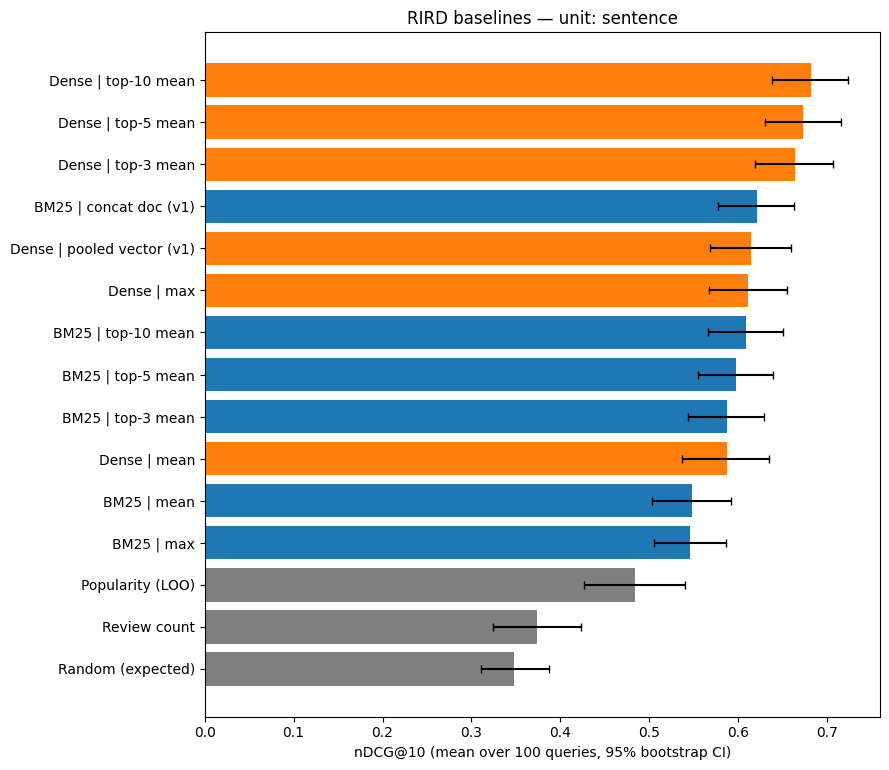

In [28]:
import matplotlib.pyplot as plt

order  = comparison_df.index[::-1]
means  = np.array([per_query[n][PRIMARY].mean() for n in order])
cis    = np.array([bootstrap_ci(per_query[n][PRIMARY]) for n in order])
colors = ['tab:blue' if n.startswith('BM25') else 'tab:orange' if n.startswith('Dense') else 'tab:gray'
          for n in order]

fig, ax = plt.subplots(figsize=(9, 0.42 * len(order) + 1.5))
ax.barh(order, means, xerr=[means - cis[:, 0], cis[:, 1] - means], color=colors, capsize=3)
ax.set_xlabel(f'{PRIMARY} (mean over {len(queries)} queries, 95% bootstrap CI)')
ax.set_title(f'RIRD baselines — unit: {UNIT}')
plt.tight_layout()
plt.show()

In [29]:
comparison_df.to_csv(CACHE_DIR / f'results_{UNIT}.csv')
pd.concat(per_query, names=['Model', 'query']).to_csv(CACHE_DIR / f'per_query_{UNIT}.csv')

# A4: save restaurant rankings and the top evidence units for every shared-unit run.
EVIDENCE_K = max(TOP_KS)
ranking_rows, evidence_rows = [], []
for model_name, run in retrieval_runs.items():
    unit_scores = run['unit_scores']
    restaurant_scores = run['restaurant_scores']
    for query_i, query in enumerate(queries):
        ranked_positions = np.argsort(-restaurant_scores[query_i], kind='stable')
        for restaurant_rank, restaurant_pos in enumerate(ranked_positions, start=1):
            bid = corpus_ids[restaurant_pos]
            ranking_rows.append({
                'model': model_name.split(' | ', 1)[0],
                'aggregation': model_name.split(' | ', 1)[1],
                'unit': UNIT,
                'query': query,
                'restaurant_id': bid,
                'restaurant_rank': restaurant_rank,
                'restaurant_score': restaurant_scores[query_i, restaurant_pos],
                'seed': SEED,
            })
            candidate_positions = unit_idx[bid]
            evidence_order = np.argsort(-unit_scores[query_i, candidate_positions], kind='stable')[:EVIDENCE_K]
            for evidence_rank, local_pos in enumerate(evidence_order, start=1):
                unit_pos = candidate_positions[local_pos]
                unit_row = units.iloc[unit_pos]
                evidence_rows.append({
                    'model': model_name.split(' | ', 1)[0],
                    'aggregation': model_name.split(' | ', 1)[1],
                    'unit': UNIT,
                    'query': query,
                    'restaurant_id': bid,
                    'restaurant_rank': restaurant_rank,
                    'restaurant_score': restaurant_scores[query_i, restaurant_pos],
                    'evidence_rank': evidence_rank,
                    'unit_score': unit_scores[query_i, unit_pos],
                    'unit_id': int(unit_pos),
                    'review_row_id': int(unit_row['review_row_id']),
                    'text': unit_row['text'],
                    'seed': SEED,
                })
ranking_exports = pd.DataFrame(ranking_rows)
evidence_exports = pd.DataFrame(evidence_rows)
ranking_exports.to_csv(CACHE_DIR / f'rankings_{UNIT}.csv', index=False)
evidence_exports.to_csv(CACHE_DIR / f'evidence_{UNIT}.csv', index=False)
print(f'Saved results, {len(ranking_exports):,} ranking rows, and {len(evidence_exports):,} evidence rows to', CACHE_DIR)

Saved results, 50,000 ranking rows, and 500,000 evidence rows to /content/cache


## 9. How to Read the Results

- **Dense vs BM25** — use the Family A table. A row is a real difference only if `sig. @0.05` is True
  and the CI of the difference does not include 0.
- **Is a model useful at all?** — use the Family B table. A model that does not beat `Popularity (LOO)`
  is mostly ranking restaurants that are relevant to everything, not matching the query.
- **Did the fix help?** — use the Family C table.
- **Not covered here:** `max` and `top-k mean` can favour restaurants with more reviews (more chances
  for one high-scoring unit). The volume control in action item A3 (subsample every restaurant to the
  same number of reviews) is still needed before making claims about fusion.
- To run the sentence-level version, set `UNIT = 'sentence'` in Section 0 and run all again.